 ## Practical Assistant Agent

---

## What you will build

A **Practical Assistant Agent** - a real, useful tool AI Agent.

- Talks to **at least 2 real external services** (Notion, GitHub, Gmail, Calendar, Slack — pick any 2+).
- Has **memory** so it can hold a multi-turn conversation.
- **Stops and asks the human** before doing anything destructive or irreversible (sending an email, deleting a file, posting publicly, creating a calendar event).

You can use custom python functions as tools, free APIs or any other API you want to try.

---
## Examples of free APIs you can use (no OAuth, mostly no key)

Pick **one or two** of these. Quick reference:

| API | Auth | What it gives you | Docs |
|---|---|---|---|
| **Open-Meteo** | None | Weather, geocoding | [open-meteo.com](https://open-meteo.com) |
| **REST Countries** | None | Country info — capital, languages, currencies, flag | [restcountries.com](https://restcountries.com) |
| **Wikipedia** | None | Topic summaries (via `langchain_community.tools.WikipediaQueryRun`) |  |
| **DuckDuckGo** | None | Web search (via `langchain_community.tools.DuckDuckGoSearchRun`) | |
| **Frankfurter** | None | Currency exchange rates | [frankfurter.app](https://www.frankfurter.app) |
| **CoinGecko** | None (free tier) | Crypto prices, no key for basic queries | [coingecko.com/api](https://www.coingecko.com/en/api) |
| **Nager.Date** | None | Public holidays per country/year | [date.nager.at](https://date.nager.at) |
| **Open Library** | None | Books — search, author info | [openlibrary.org/developers/api](https://openlibrary.org/developers/api) |
| **Bored API** | None | Random activity suggestions | [bored.api.lewagon.com](https://bored.api.lewagon.com) |
| **Numbers API** | None | Math/date/year facts | [numbersapi.com](http://numbersapi.com) |
| **Universities** | None | List of universities by country | hipolabs.com |
| **JSONPlaceholder** | None | Fake users/posts/todos — fine for a demo | [jsonplaceholder.typicode.com](https://jsonplaceholder.typicode.com) |


---
## Examples of custom Python tools

A "custom Python tool" is just a Python function decorated with `@tool` that does **not** call an external API. It operates on in-memory data. Examples:

| Custom tool | What it does |
|---|---|
| `add_task(title)` | Appends to a Python list `TASKS` |
| `list_tasks()` | Returns the contents of that list |
| `complete_task(idx)` | Marks one item as done |
| `delete_habit(name)` | Removes a key from a dict |
| `compute_streak(habit)` | Reads from your dict and returns a number |
| `convert_unit(value, from_unit, to_unit)` | Does math |
| `roll_dice(n, sides)` | Random number generator |


---
## What you submit


1. **Title + one-paragraph description** of what your agent does.
2. **Setup** — install + API key (empty).
3. **Tools** — every `@tool` you wrote, with docstrings.
4. **State + graph** — `StateGraph` definition. Compile and call `.get_graph().draw_mermaid_png()` to render a diagram.
5. **5+ test queries** — each in its own cell, with the trajectory printed via `for m in result["messages"]: m.pretty_print()`.
6. **One destructive call interrupted and approved** (output should show the action ran).
7. **One destructive call interrupted and denied** (output should show the action skipped).
8. **Eval table** — markdown cell with the table below filled in.

### 2. Eval table (inside the notebook)

| # | Query | Expected | Pass? | Notes |
|---|---|---|---|---|
| 1 | "..." | "..." | ✅ / ❌ | brief comment |
| 2 | ... | ... | ... | ... |

5 entries minimum. Be honest - a partial pass is still informative.


- **Streamlit app** — simple chat UI on top of your agent.
- **GitHub repo** with a README — share the link instead of a zip.


**Internship Application Tracker Agent**

ეს აგენტი ეხმარება სტუდენტს სტაჟირების აპლიკაციების თვალყურის დევნებაში: ამატებს აპლიკაციებს, ცვლის სტატუსს, ეძებს ინფორმაციას კომპანიის შესახებ (Wikipedia) და ამოწმებს ინტერვიუს ქალაქის ამინდს (Open-Meteo). აპლიკაციის წაშლამდე აგენტი ითხოვს მომხმარებლის დადასტურებას.

## Setup

pip install langgraph langchain-groq requests

GROQ_API_KEY=""

In [36]:
%pip install -q langgraph langchain-groq requests


In [4]:
import os
from google.colab import userdata
os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY").strip()
print("API key loaded")

API key loaded


In [7]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0, max_tokens=2000)
print(llm.invoke("Say hello in one short sentence.").content)

Hello!


In [6]:
import os, requests
r = requests.get(
    "https://api.groq.com/openai/v1/models",
    headers={"Authorization": f"Bearer {os.environ['GROQ_API_KEY']}"},
    timeout=20,
)
for m in r.json()["data"]:
    print(m["id"])

allam-2-7b
canopylabs/orpheus-arabic-saudi
openai/gpt-oss-20b
openai/gpt-oss-safeguard-20b
meta-llama/llama-prompt-guard-2-22m
whisper-large-v3
canopylabs/orpheus-v1-english
openai/gpt-oss-120b
qwen/qwen3.8-27b
meta-llama/llama-prompt-guard-2-86m
whisper-large-v3-turbo


In [8]:
import requests
from langchain_core.tools import tool
from langgraph.types import interrupt

APPLICATIONS = []  # {"company":..., "role":..., "status":...}

@tool
def add_application(company: str, role: str) -> str:
    """Add a new internship application with the status 'Applied'."""
    APPLICATIONS.append({"company": company, "role": role, "status": "Applied"})
    return f"Added: {role} at {company} (Applied)"

@tool
def list_applications() -> str:
    """List all saved internship applications with their statuses."""
    if not APPLICATIONS:
        return "No applications yet."
    return "\n".join(f"- {a['company']} | {a['role']} | {a['status']}" for a in APPLICATIONS)

@tool
def update_status(company: str, status: str) -> str:
    """Update the status (e.g. Applied, Interview, Rejected, Offer) of an application by company name."""
    for a in APPLICATIONS:
        if a["company"].lower() == company.lower():
            a["status"] = status
            return f"{a['company']} status updated to {status}"
    return f"No application found for {company}"

@tool
def get_company_info(company: str) -> str:
    """Get a short summary about a company from Wikipedia."""
    r = requests.get(
        f"https://en.wikipedia.org/api/rest_v1/page/summary/{company.replace(' ', '_')}",
        headers={"User-Agent": "internship-agent/1.0"}, timeout=20)
    if r.status_code != 200:
        return f"No Wikipedia summary found for {company}"
    return r.json().get("extract", "No summary available")[:600]

@tool
def get_city_weather(city: str) -> str:
    """Get the current temperature in Celsius for a city (useful for interview day)."""
    geo = requests.get("https://geocoding-api.open-meteo.com/v1/search",
                       params={"name": city, "count": 1}, timeout=20).json()
    if not geo.get("results"):
        return f"City not found: {city}"
    g = geo["results"][0]
    w = requests.get("https://api.open-meteo.com/v1/forecast",
                     params={"latitude": g["latitude"], "longitude": g["longitude"],
                             "current": "temperature_2m"}, timeout=20)
    w.raise_for_status()
    return f"{g['name']}: {w.json()['current']['temperature_2m']} °C"

@tool
def delete_application(company: str) -> str:
    """Delete an application by company name. Requires user approval first."""
    target = next((a for a in APPLICATIONS if a["company"].lower() == company.lower()), None)
    if target is None:
        return f"No application found for {company}"
    approved = interrupt(f"Are you sure you want to delete the application to {target['company']}?")
    if approved is True:
        APPLICATIONS.remove(target)
        return f"Deleted application to {target['company']}"
    return "Action cancelled by user. Nothing was deleted."

tools = [add_application, list_applications, update_status,
         get_company_info, get_city_weather, delete_application]

In [9]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

class State(TypedDict):
    messages: Annotated[list, add_messages]

llm_with_tools = llm.bind_tools(tools)
SYSTEM = SystemMessage(content=(
    "You are an Internship Application Tracker assistant. Use tools to manage "
    "applications, look up company info and check weather. For deletions always "
    "call delete_application and never delete without it."))

def assistant(state: State):
    return {"messages": [llm_with_tools.invoke([SYSTEM] + state["messages"])]}

builder = StateGraph(State)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")

graph = builder.compile(checkpointer=InMemorySaver())

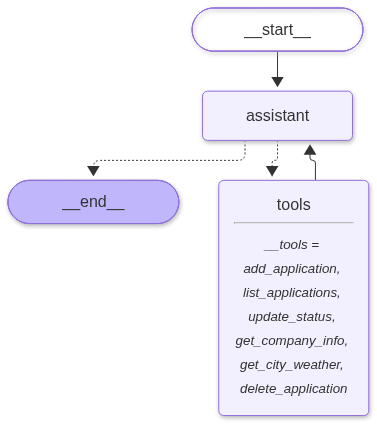

In [10]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
config = {"configurable": {"thread_id": "demo-1"}}

result = graph.invoke({"messages": [("user", "Add an application: Google, Data Analyst Intern")]}, config)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Add an application: Google, Data Analyst Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_5dc10190-9487-4297-b2e9-ed1293d90420)
 Call ID: fc_5dc10190-9487-4297-b2e9-ed1293d90420
  Args:
    company: Google
    role: Data Analyst Intern
================================= Tool Message =================================
Name: add_application

Added: Data Analyst Intern at Google (Applied)
================================== Ai Message ==================================

Your application has been added:

- **Company:** Google  
- **Role:** Data Analyst Intern  
- **Status:** Applied  

Let me know if you’d like to view all applications, update a status, or anything else!


In [12]:
result = graph.invoke({"messages": [("user", "Add: TBC Bank, Finance Intern. Then show my applications.")]}, config)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Add an application: Google, Data Analyst Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_5dc10190-9487-4297-b2e9-ed1293d90420)
 Call ID: fc_5dc10190-9487-4297-b2e9-ed1293d90420
  Args:
    company: Google
    role: Data Analyst Intern
================================= Tool Message =================================
Name: add_application

Added: Data Analyst Intern at Google (Applied)
================================== Ai Message ==================================

Your application has been added:

- **Company:** Google  
- **Role:** Data Analyst Intern  
- **Status:** Applied  

Let me know if you’d like to view all applications, update a status, or anything else!
================================ Human Message =================================

Add: TBC Bank, Finance Intern. Then show my applications.
================================

In [13]:
result = graph.invoke({"messages": [("user", "Tell me about TBC Bank")]}, config)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Add an application: Google, Data Analyst Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_5dc10190-9487-4297-b2e9-ed1293d90420)
 Call ID: fc_5dc10190-9487-4297-b2e9-ed1293d90420
  Args:
    company: Google
    role: Data Analyst Intern
================================= Tool Message =================================
Name: add_application

Added: Data Analyst Intern at Google (Applied)
================================== Ai Message ==================================

Your application has been added:

- **Company:** Google  
- **Role:** Data Analyst Intern  
- **Status:** Applied  

Let me know if you’d like to view all applications, update a status, or anything else!
================================ Human Message =================================

Add: TBC Bank, Finance Intern. Then show my applications.
================================

In [14]:
result = graph.invoke({"messages": [("user", "What's the weather in Tbilisi?")]}, config)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Add an application: Google, Data Analyst Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_5dc10190-9487-4297-b2e9-ed1293d90420)
 Call ID: fc_5dc10190-9487-4297-b2e9-ed1293d90420
  Args:
    company: Google
    role: Data Analyst Intern
================================= Tool Message =================================
Name: add_application

Added: Data Analyst Intern at Google (Applied)
================================== Ai Message ==================================

Your application has been added:

- **Company:** Google  
- **Role:** Data Analyst Intern  
- **Status:** Applied  

Let me know if you’d like to view all applications, update a status, or anything else!
================================ Human Message =================================

Add: TBC Bank, Finance Intern. Then show my applications.
================================

In [15]:
result = graph.invoke({"messages": [("user", "Update Google status to Interview")]}, config)
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Add an application: Google, Data Analyst Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_5dc10190-9487-4297-b2e9-ed1293d90420)
 Call ID: fc_5dc10190-9487-4297-b2e9-ed1293d90420
  Args:
    company: Google
    role: Data Analyst Intern
================================= Tool Message =================================
Name: add_application

Added: Data Analyst Intern at Google (Applied)
================================== Ai Message ==================================

Your application has been added:

- **Company:** Google  
- **Role:** Data Analyst Intern  
- **Status:** Applied  

Let me know if you’d like to view all applications, update a status, or anything else!
================================ Human Message =================================

Add: TBC Bank, Finance Intern. Then show my applications.
================================

In [16]:
from langgraph.types import Command

cfg_yes = {"configurable": {"thread_id": "approve-1"}}
graph.invoke({"messages": [("user", "Add: Test Corp, Intern")]}, cfg_yes)

r = graph.invoke({"messages": [("user", "Delete my Test Corp application")]}, cfg_yes)
print("INTERRUPT:", r["__interrupt__"])      # აგენტი ითხოვს დადასტურებას

r = graph.invoke(Command(resume=True), cfg_yes)   # მომხმარებელი ეთანხმება
for m in r["messages"]:
    m.pretty_print()

print(list_applications.invoke({}))           # Test Corp უნდა გამქრალიყო

INTERRUPT: [Interrupt(value='Are you sure you want to delete the application to Test Corp?', id='cf77acd5b39ce08ad69b2ffb9b3386f9', response_schema=None)]
================================ Human Message =================================

Add: Test Corp, Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_6e61fab1-4b8d-4120-b1fd-64352880c0c1)
 Call ID: fc_6e61fab1-4b8d-4120-b1fd-64352880c0c1
  Args:
    company: Test Corp
    role: Intern
================================= Tool Message =================================
Name: add_application

Added: Intern at Test Corp (Applied)
================================== Ai Message ==================================

Your application has been added:

- **Company:** Test Corp  
- **Role:** Intern  
- **Status:** Applied  

Let me know if you’d like to add more applications, update a status, view your list, or anything else!
================================ Human Message =========

In [17]:
cfg_no = {"configurable": {"thread_id": "deny-1"}}
graph.invoke({"messages": [("user", "Add: Keep Corp, Intern")]}, cfg_no)

r = graph.invoke({"messages": [("user", "Delete my Keep Corp application")]}, cfg_no)
print("INTERRUPT:", r["__interrupt__"])

r = graph.invoke(Command(resume=False), cfg_no)   # მომხმარებელი უარს ამბობს
for m in r["messages"]:
    m.pretty_print()

print(list_applications.invoke({}))           # Keep Corp უნდა დარჩენილიყო

KeyError: '__interrupt__'

In [18]:
cfg_no = {"configurable": {"thread_id": "deny-2"}}
graph.invoke({"messages": [("user", "Add: Keep Corp, Intern")]}, cfg_no)

r = graph.invoke({"messages": [("user", "Use the delete_application tool to delete Keep Corp")]}, cfg_no)
print("INTERRUPTED:", "__interrupt__" in r)
print(r["messages"][-1].content)

INTERRUPTED: True



In [19]:
print("INTERRUPT:", r["__interrupt__"])

r = graph.invoke(Command(resume=False), cfg_no)
for m in r["messages"]:
    m.pretty_print()

print(list_applications.invoke({}))

INTERRUPT: [Interrupt(value='Are you sure you want to delete the application to Keep Corp?', id='877887f6cbf0b9091efeae03aed9ca80', response_schema=None)]
================================ Human Message =================================

Add: Keep Corp, Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_65afc487-784b-48b5-8025-202f508cf334)
 Call ID: fc_65afc487-784b-48b5-8025-202f508cf334
  Args:
    company: Keep Corp
    role: Intern
================================= Tool Message =================================
Name: add_application

Added: Intern at Keep Corp (Applied)
================================== Ai Message ==================================

Your application for the **Intern** position at **Keep Corp** has been added with the status **Applied**. Let me know if you’d like to view all applications, update a status, or anything else!
================================ Human Message ==========================

In [20]:
APPLICATIONS[:] = [a for i, a in enumerate(APPLICATIONS) if a not in APPLICATIONS[:i]]
print(list_applications.invoke({}))

- Google | Data Analyst Intern | Interview
- TBC Bank | Finance Intern | Applied
- Keep Corp | Intern | Applied


In [21]:
SYSTEM = SystemMessage(content=(
    "You are an Internship Application Tracker assistant. Use tools to manage "
    "applications, look up company info and check weather. For deletions always "
    "call delete_application and never delete without it. If a tool result says "
    "the action was cancelled by the user, do NOT call the tool again; just tell "
    "the user the deletion was cancelled and nothing was deleted."))
print("Prompt updated")

Prompt updated


In [22]:
cfg_no = {"configurable": {"thread_id": "deny-3"}}
graph.invoke({"messages": [("user", "Add: Cancel Corp, Intern")]}, cfg_no)

r = graph.invoke({"messages": [("user", "Use the delete_application tool to delete Cancel Corp")]}, cfg_no)
print("INTERRUPT:", r["__interrupt__"])

r = graph.invoke(Command(resume=False), cfg_no)
for m in r["messages"]:
    m.pretty_print()

print("INTERRUPTED AGAIN:", "__interrupt__" in r)
print(list_applications.invoke({}))

INTERRUPT: [Interrupt(value='Are you sure you want to delete the application to Cancel Corp?', id='710c42042081559c8169362b153e130a', response_schema=None)]
================================ Human Message =================================

Add: Cancel Corp, Intern
================================== Ai Message ==================================
Tool Calls:
  add_application (fc_8604d70c-a967-4fb2-989a-312a47b9d0a4)
 Call ID: fc_8604d70c-a967-4fb2-989a-312a47b9d0a4
  Args:
    company: Cancel Corp
    role: Intern
================================= Tool Message =================================
Name: add_application

Added: Intern at Cancel Corp (Applied)
================================== Ai Message ==================================

Your application for the **Intern** position at **Cancel Corp** has been added with the status **Applied**. Let me know if you’d like to view all your applications, update a status, or anything else!
================================ Human Message ===========

## Evaluation Table

| # | Query | Expected | Pass? | Notes |
|---|-------|----------|-------|-------|
| 1 | Add Google application | Application added | ✅ | `add_application` სწორად გამოიძახა |
| 2 | Add TBC Bank + show applications | Both apps listed | ✅ | ორი Tool ზედიზედ, მეხსიერება მუშაობს |
| 3 | Tell me about TBC Bank | Wikipedia summary | ✅ | Wikipedia-დან ამოიღო, მაგრამ პასუხს მოდელის საკუთარი დეტალებიც დაემატა |
| 4 | Weather in Tbilisi | Temperature returned | ✅ | Open-Meteo-დან 11.5 °C |
| 5 | Update Google status to Interview | Status updated | ✅ | `update_status` გამოიძახა |
| 6 | Delete Test Corp (approved) | Approval requested, then deleted | ✅ | `interrupt()` გააჩერა, `resume=True`-ის შემდეგ წაიშალა |
| 7 | Delete Cancel Corp (denied) | Approval requested, not deleted | ✅ | უარის შემდეგ არაფერი წაშლილა. თავიდან მოდელი უარის მერე Tool-ს ხელახლა იძახებდა, პრომპტის გაუმჯობესებით გასწორდა |
| 8 | "Delete my Keep Corp application" (ზოგადი ფრაზა) | Approval requested | ❌ | პირველ ცდაზე მოდელმა Tool არ გამოიძახა; პირდაპირი ფრაზით ("Use the delete_application tool...") მუშაობს |

In [33]:
%%writefile agent.py
import os
import requests
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import SystemMessage
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import interrupt

APPLICATIONS = []  # in-memory list of {"company", "role", "status"}


@tool
def add_application(company: str, role: str) -> str:
    """Add a new internship application with the status 'Applied'."""
    APPLICATIONS.append({"company": company, "role": role, "status": "Applied"})
    return f"Added: {role} at {company} (Applied)"


@tool
def list_applications() -> str:
    """List all saved internship applications with their statuses."""
    if not APPLICATIONS:
        return "No applications yet."
    return "\n".join(f"- {a['company']} | {a['role']} | {a['status']}" for a in APPLICATIONS)


@tool
def update_status(company: str, status: str) -> str:
    """Update the status (e.g. Applied, Interview, Rejected, Offer) of an application by company name."""
    for a in APPLICATIONS:
        if a["company"].lower() == company.lower():
            a["status"] = status
            return f"{a['company']} status updated to {status}"
    return f"No application found for {company}"


@tool
def get_company_info(company: str) -> str:
    """Get a short summary about a company from Wikipedia."""
    r = requests.get(
        f"https://en.wikipedia.org/api/rest_v1/page/summary/{company.replace(' ', '_')}",
        headers={"User-Agent": "internship-agent/1.0"}, timeout=20)
    if r.status_code != 200:
        return f"No Wikipedia summary found for {company}"
    return r.json().get("extract", "No summary available")[:600]


@tool
def get_city_weather(city: str) -> str:
    """Get the current temperature in Celsius for a city (useful for interview day)."""
    geo = requests.get("https://geocoding-api.open-meteo.com/v1/search",
                       params={"name": city, "count": 1}, timeout=20).json()
    if not geo.get("results"):
        return f"City not found: {city}"
    g = geo["results"][0]
    w = requests.get("https://api.open-meteo.com/v1/forecast",
                     params={"latitude": g["latitude"], "longitude": g["longitude"],
                             "current": "temperature_2m"}, timeout=20)
    w.raise_for_status()
    return f"{g['name']}: {w.json()['current']['temperature_2m']} °C"


@tool
def delete_application(company: str) -> str:
    """Delete an application by company name. Requires user approval first."""
    target = next((a for a in APPLICATIONS if a["company"].lower() == company.lower()), None)
    if target is None:
        return f"No application found for {company}"
    approved = interrupt(f"Are you sure you want to delete the application to {target['company']}?")
    if approved is True:
        APPLICATIONS.remove(target)
        return f"Deleted application to {target['company']}"
    return "Action cancelled by user. Nothing was deleted."


TOOLS = [add_application, list_applications, update_status,
         get_company_info, get_city_weather, delete_application]

SYSTEM = SystemMessage(content="""You are an Internship Application Tracker assistant.
Use tools to manage applications, look up company info and check weather.
For deletions always call delete_application and never delete without it.
If a tool result says the action was cancelled by the user, do NOT call the tool again.
Just tell the user the deletion was cancelled and nothing was deleted.""")


class State(TypedDict):
    messages: Annotated[list, add_messages]


def build_graph():
    llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0, max_tokens=2000)
    llm_with_tools = llm.bind_tools(TOOLS)

    def assistant(state: State):
        return {"messages": [llm_with_tools.invoke([SYSTEM] + state["messages"])]}

    builder = StateGraph(State)
    builder.add_node("assistant", assistant)
    builder.add_node("tools", ToolNode(TOOLS))
    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", tools_condition)
    builder.add_edge("tools", "assistant")
    return builder.compile(checkpointer=InMemorySaver())

Overwriting agent.py


In [24]:
%%writefile main.py
import os
import getpass
from langgraph.types import Command

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass.getpass("Enter GROQ_API_KEY: ").strip()

from agent import build_graph

graph = build_graph()
config = {"configurable": {"thread_id": "cli-1"}}

print("Internship Tracker Agent. Type 'exit' to quit.")
while True:
    text = input("\nYou: ").strip()
    if text.lower() in ("exit", "quit"):
        break
    result = graph.invoke({"messages": [("user", text)]}, config)
    while "__interrupt__" in result:
        question = result["__interrupt__"][0].value
        answer = input(f"\n[CONFIRM] {question} (yes/no): ").strip().lower()
        result = graph.invoke(Command(resume=answer in ("yes", "y")), config)
    print("\nAgent:", result["messages"][-1].content)

Writing main.py


In [25]:
%%writefile app.py
import os
import uuid
import streamlit as st
from langgraph.types import Command

try:
    os.environ["GROQ_API_KEY"] = st.secrets["GROQ_API_KEY"]
except Exception:
    pass

from agent import build_graph

st.title("Internship Application Tracker")
st.caption("Track applications, check company info and weather, delete safely with approval.")

if "graph" not in st.session_state:
    st.session_state.graph = build_graph()
    st.session_state.config = {"configurable": {"thread_id": str(uuid.uuid4())}}
    st.session_state.history = []
    st.session_state.pending = None

graph, config = st.session_state.graph, st.session_state.config


def handle(result):
    if "__interrupt__" in result:
        st.session_state.pending = result["__interrupt__"][0].value
    else:
        st.session_state.pending = None
        st.session_state.history.append(("assistant", result["messages"][-1].content))


for role, text in st.session_state.history:
    with st.chat_message(role):
        st.write(text)

if st.session_state.pending:
    st.warning(st.session_state.pending)
    c1, c2 = st.columns(2)
    if c1.button("✅ Approve"):
        handle(graph.invoke(Command(resume=True), config))
        st.rerun()
    if c2.button("❌ Deny"):
        handle(graph.invoke(Command(resume=False), config))
        st.rerun()
else:
    prompt = st.chat_input("Ask the agent...")
    if prompt:
        st.session_state.history.append(("user", prompt))
        try:
            handle(graph.invoke({"messages": [("user", prompt)]}, config))
        except Exception as e:
            st.session_state.history.append(("assistant", f"Error: {e}"))
        st.rerun()

Writing app.py


In [26]:
%%writefile requirements.txt
langgraph
langchain-groq
langchain-core
requests
streamlit

Writing requirements.txt


In [27]:
%%writefile .gitignore
.env
.streamlit/secrets.toml
.venv/
__pycache__/

Writing .gitignore


In [28]:
%%writefile README.md
# Internship Application Tracker Agent

An AI agent (LangGraph + Groq) that helps a student track internship applications:
add applications, update their status, look up company info on Wikipedia and check
the weather for an interview city (Open-Meteo). Before deleting an application the
agent pauses and asks the user for approval (human-in-the-loop with interrupt()).

## Tools
- add_application, list_applications, update_status
- delete_application (requires user approval)
- get_company_info (Wikipedia API)
- get_city_weather (Open-Meteo API)

## Setup
Install the libraries:

    pip install -r requirements.txt

Set your Groq API key (never commit a real key):

    export GROQ_API_KEY=""

## Run
- CLI: python main.py
- Streamlit: streamlit run app.py
- Notebook: open the .ipynb file in Google Colab (add GROQ_API_KEY to Colab Secrets)

## Features
StateGraph, conversation memory (InMemorySaver), approval flow (approve / deny),
5+ test queries and an evaluation table in the notebook.

## Limitations
Applications are stored in memory and reset when the app restarts. The LLM may
occasionally skip a tool call for vague phrasing (see the evaluation table).

Writing README.md


In [31]:
from agent import build_graph
g = build_graph()
print("agent.py works")

!zip -q project.zip agent.py main.py app.py requirements.txt .gitignore README.md
from google.colab import files
files.download("project.zip")

ImportError: cannot import name 'build_graph' from 'agent' (/content/agent.py)

In [32]:
!grep -n "def build_graph" agent.py
!tail -5 agent.py

SYSTEM = SystemMessage(content="""You are an Internship Application Tracker assistant.
Use tools to manage applications, look up company info and check weather.
For deletions always call delete_application and never delete without it.
If a tool result says the action was cancelled by the user, do NOT call the tool again.
Just tell the user the deletion was cancelled and nothing was deleted.""")


In [34]:
import sys
sys.modules.pop("agent", None)   # ძველი ქეშის გასუფთავება

!python -m py_compile agent.py && echo "agent.py OK"

from agent import build_graph
g = build_graph()
print("agent.py works")

agent.py OK
agent.py works


In [35]:
!zip -q project.zip agent.py main.py app.py requirements.txt .gitignore README.md
from google.colab import files
files.download("project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>